In [1]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [15]:
# The uncertainty factors, or dnb nodes
factortuples = [
    # Ajattomat
    ("HHA", 3, ()),  # 0   
    ("GER", 2, ()),  # 1
    ("OMA", 2, ()),  # 2

    # Nykyhetki
    ("PIS0", 4, ()), # 3
    ("PIH0", 5, (0,3,)), # 4
    ("LYS0", 4, (3,4,)), # 5
    ("LYH0", 7, (0,3,4,5,)), # 6
    ("AST0", 3, (1,2,4,6,)), # 7
    ("KUO0", 2, (3,4,5,6,)), # 8

    # Viive
    ("PISt", 4, (3,4,5,6,)), # 9
    ("PIHt", 5, (1,2,4,6,9,)), # 10
    ("LYSt", 4, (1,2,5,6,9,10,)), # 11
    ("LYHt", 7, (1,2,6,9,10,11,)), # 12
    ("ASTt", 3, (10,12,)), # 13
    ("KUOt", 2, (9,10,11,12,)), # 14
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]
desc = """
Tilalistaus:
* Lyhytaikainen sairaus (LYS)
	* 0 Terve (ei akuuttia tilaa)
	* 1 Lievä (luultavasti paranee itsestään ilman hoitoa, esim. flunssa)
	* 2 Vakava (Vaatii hoitoa tai pitkäaikaisten ongelmien riski on suuri)
	* 3 Hengenvaarallinen (Vaatii välitönta hoitoa tai kuoleman todennäköisyys on suuri)
* Pitkäaikainen sairaus (PIS)
	* 0 Terve (Ei pitkäaikaisia vaivoja)
	* 1 Lievä (Ei vaadi aktiivista hoitoa)
	* 2 Vakava (Vaatii jatkuvaa hoitoa)
	* 3 Hengenvaarallinen (Vaatii jatkuvaa hoitoa kuoleman välttämiseksi)
* Hoitoonhakeutumisalttius (HHA)
	* 0 Ramppaaja (Käy tarpeettomasti hakemassa hoitoa)
	* 1 Normaali (Hakeutuu hoitoon lähinnä vakavissa tilanteissa)
	* 2 Änkyrä (Ei hakeudu hoitoon ellei joku pakota)
* Lyhytaikainen hoito (akuutti) (LYH)
	* 0 Ei mitään
	* 1 Terveyskeskus
	* 2 Päivystys
	* 3 Sairaala
	* 4 Kotisairaala????
	* 5 Lyhytaikainen kuntoutus
	* 6 Arviointiyksikkö
* Pitkäaikainen hoito (PIH)
	* 0 Ei mitään
	* 1 Omaishoito
	* 2 Kotihoito
	* 3 Ympärivuorokaiutinen palveluasuminen
	* 4 Laitospalvelu
* Geriatriapalikka (Hoitaako geriatritiimi päivystyksessä) (GER)
	* 0 Kyllä
	* 1 Ei
* Omalääkäri (OMA)
	* 0 Kyllä
	* 1 Ei
* Asiakastyytyväisyys (AST)
	* 0 Hyvä
	* 1 Keskinkertainen
	* 2 Huono
* Kuollut (KUO)
	* 0 Kyllä
	* 1 Ei
"""

In [3]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])
kuo_mar = np.array([0.00015, 1-0.00015])

In [4]:
df = pd.read_csv("ci-data/cross-impact-healthcare-sheet.csv")
df = df.iloc[8:, 3:]
df = df.astype(float)
ls = list(map(lambda x : x[1], factortuples))
print(ls)
lo = []
for i, l in enumerate(ls):
    lo.append(sum(ls[:i]))
print(lo)
print("---")

cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        print(f"({parent_index}, {fi})")
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        #cross_impacts[(parent_index, fi)] = np.zeros((parent_dim, factor_dim))
        cross_impacts[(parent_index, fi)] = np.array(df.iloc[lo[parent_index]:lo[parent_index]+ls[parent_index],lo[fi]:lo[fi]+ls[fi]])
        print(cross_impacts[parent_index, fi])

[3, 2, 2, 4, 5, 4, 7, 3, 2, 4, 5, 4, 7, 3, 2]
[0, 3, 5, 7, 11, 16, 20, 27, 30, 32, 36, 41, 45, 52, 55]
---
(0, 4)
[[ 2. -2. -2. -2. -2.]
 [ 0.  0.  0.  0.  0.]
 [-2.  2.  2.  2.  2.]]
(3, 4)
[[ 3. -3. -3. -3. -3.]
 [ 2. -2. -2. -2. -2.]
 [-2.  2.  2.  1.  1.]
 [-3.  2.  2.  3.  3.]]
(3, 5)
[[3. 2. 1. 0.]
 [2. 3. 2. 1.]
 [1. 2. 3. 2.]
 [0. 1. 2. 3.]]
(4, 5)
[[1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
(0, 6)
[[ 2. -2. -2. -2. -2. -2. -2.]
 [ 0.  0.  0.  0.  0.  0.  0.]
 [-2.  2.  2.  2.  2.  2.  2.]]
(3, 6)
[[ 2. -2. -2. -2. -2. -2. -2.]
 [ 1. -1. -1. -1. -1. -1. -1.]
 [-1.  1.  1.  1.  1.  1.  1.]
 [-2.  2.  2.  2.  2.  2.  2.]]
(4, 6)
[[ 1.  0.  0. -1. -1. -1. -1.]
 [ 0.  1.  0.  0.  0.  0.  0.]
 [ 0.  1.  1.  0. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  1.  1.]
 [ 0.  0.  0.  0.  0.  1.  1.]]
(5, 6)
[[ 3.  1.  1. -2. -3. -3. -3.]
 [ 1.  1.  1. -1. -2. -3. -3.]
 [-1.  2.  3.  3.  3.  2.  1.]
 [-3. -3.  3.  3.  3.  1. -1.]]
(1, 7)
[[ 1.  0. -1.]
 [-1.  0.  1.]]

In [5]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

(CVXPY) Nov 02 04:49:37 PM: Your problem has 3 variables, 4 constraints, and 0 parameters.
(CVXPY) Nov 02 04:49:37 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 02 04:49:37 PM: DCP verification time: 0.0001 seconds.
(CVXPY) Nov 02 04:49:37 PM: Expression tree has 2 nodes.
(CVXPY) Nov 02 04:49:37 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 02 04:49:37 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 02 04:49:37 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 02 04:49:37 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 02 04:49:37 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Nov 02 04:49:37 PM: Applying reduction Dcp2Cone
(CVXPY) Nov 02 04:49:37 PM: Applying reduction CvxAttr2Constr
(CVXPY) Nov 02 04:49:37 PM: App

                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
-------------------------------------------------------------
           Clarabel.rs v0.11.1  -  Clever Acronym                

                   (c) Paul Goulart                          
                University of Oxford, 2022                   
-------------------------------------------------------------

problem:
  variables     = 3
  constraints  

(CVXPY) Nov 02 04:49:37 PM: Problem status: optimal
(CVXPY) Nov 02 04:49:37 PM: Optimal value: 0.000e+00
(CVXPY) Nov 02 04:49:37 PM: Compilation took 2.207e-02 seconds
(CVXPY) Nov 02 04:49:37 PM: Solver (including time spent in interface) took 3.314e-03 seconds
(CVXPY) Nov 02 04:49:37 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Nov 02 04:49:37 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 02 04:49:37 PM: DCP verification time: 0.0000 seconds.
(CVXPY) Nov 02 04:49:37 PM: Expression tree has 2 nodes.
(CVXPY) Nov 02 04:49:37 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 02 04:49:37 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 02 04:49:37 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 02 04:49:37 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 02 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  3.59e-01  7.48e-01  1.00e+00  1.02e+00   ------   
  1  +0.0000e+00  -1.2222e-01  1.22e-01  6.71e-02  2.13e-01  6.18e-03  2.13e-01  8.24e-01  
  2  +0.0000e+00  -9.7315e-04  9.73e-04  1.08e-03  3.35e-03  9.64e-04  4.06e-03  9.90e-01  
  3  +0.0000e+00  -9.6991e-06  9.70e-06  1.08e-05  3.35e-05  9.62e-06  4.06e-05  9.90e-01  
  4  +0.0000e+00  -9.6988e-08  9.70e-08  1.08e-07  3.35e-07  9.62e-08  4.06e-07  9.90e-01  
  5  +0.0000e+00  -9.6988e-10  9.70e-10  1.08e-09  3.35e-09  9.62e-10  4.06e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 484.797µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                 

(CVXPY) Nov 02 04:49:37 PM: Problem status: optimal
(CVXPY) Nov 02 04:49:37 PM: Optimal value: 0.000e+00
(CVXPY) Nov 02 04:49:37 PM: Compilation took 5.317e-03 seconds
(CVXPY) Nov 02 04:49:37 PM: Solver (including time spent in interface) took 1.315e-03 seconds
(CVXPY) Nov 02 04:49:37 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Nov 02 04:49:37 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 02 04:49:37 PM: DCP verification time: 0.0001 seconds.
(CVXPY) Nov 02 04:49:37 PM: Expression tree has 2 nodes.
(CVXPY) Nov 02 04:49:37 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 02 04:49:37 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 02 04:49:37 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 02 04:49:37 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 02 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  2.84e-01  6.50e-01  1.00e+00  1.13e+00   ------   
  1  +0.0000e+00  -8.8477e-02  8.85e-02  3.61e-02  1.19e-01  6.78e-03  1.59e-01  8.79e-01  
  2  +0.0000e+00  -7.0454e-04  7.05e-04  3.94e-04  1.42e-03  3.00e-04  1.93e-03  9.90e-01  
  3  +0.0000e+00  -7.0353e-06  7.04e-06  3.94e-06  1.42e-05  3.00e-06  1.93e-05  9.90e-01  
  4  +0.0000e+00  -7.0352e-08  7.04e-08  3.94e-08  1.42e-07  3.00e-08  1.93e-07  9.90e-01  
  5  +0.0000e+00  -7.0352e-10  7.04e-10  3.94e-10  1.42e-09  3.00e-10  1.93e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 57.031µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                  

... (20 outputs left out)

(CVXPY) Nov 02 04:49:50 PM: Problem status: optimal_inaccurate
(CVXPY) Nov 02 04:49:50 PM: Optimal value: 6.497e+00
(CVXPY) Nov 02 04:49:50 PM: Compilation took 3.759e-02 seconds
(CVXPY) Nov 02 04:49:50 PM: Solver (including time spent in interface) took 6.574e+00 seconds
(CVXPY) Nov 02 04:49:50 PM: Your problem has 105 variables, 38 constraints, and 0 parameters.
(CVXPY) Nov 02 04:49:50 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 02 04:49:50 PM: DCP verification time: 0.0002 seconds.
(CVXPY) Nov 02 04:49:50 PM: Expression tree has 5 nodes.
(CVXPY) Nov 02 04:49:50 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 02 04:49:50 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 02 04:49:50 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 02 04:49:50 PM: Compiling problem (target solver=OSQP).
(CVXP

10000   6.4969e+00   4.43e-05   4.66e-06  -3.66e-04   4.43e-05   1.00e-01    6.57e+00s

status:               solved inaccurate
number of iterations: 10000
optimal objective:    6.4969
dual objective:       6.4972
duality gap:          -3.6609e-04
primal-dual integral: 2.3464e+05
run time:             6.57e+00s
optimal rho estimate: 1.64e-01

-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
---------------

(CVXPY) Nov 02 04:49:50 PM: Problem status: optimal_inaccurate
(CVXPY) Nov 02 04:49:50 PM: Optimal value: 1.606e+01
(CVXPY) Nov 02 04:49:50 PM: Compilation took 1.347e-02 seconds
(CVXPY) Nov 02 04:49:50 PM: Solver (including time spent in interface) took 2.926e-01 seconds


5000   1.6055e+01   1.57e-04   3.41e-05   1.77e-04   1.77e-04   5.84e-01    1.56e-01s
5200   1.6055e+01   1.61e-04   3.33e-05   1.98e-04   1.98e-04   5.84e-01    1.62e-01s
5400   1.6055e+01   1.64e-04   3.06e-05   2.82e-04   2.82e-04   5.84e-01    1.67e-01s
5600   1.6055e+01   1.67e-04   3.04e-05   2.71e-04   2.71e-04   5.84e-01    1.73e-01s
5800   1.6055e+01   1.70e-04   2.82e-05   3.19e-04   3.19e-04   5.84e-01    1.78e-01s
6000   1.6055e+01   1.73e-04   2.80e-05   3.07e-04   3.07e-04   5.84e-01    1.83e-01s
6200   1.6055e+01   1.76e-04   2.68e-05   3.50e-04   3.50e-04   5.84e-01    1.89e-01s
6400   1.6055e+01   1.79e-04   2.66e-05   4.02e-04   4.02e-04   5.84e-01    1.94e-01s
6600   1.6055e+01   1.81e-04   2.53e-05   4.05e-04   4.05e-04   5.84e-01    2.00e-01s
6800   1.6055e+01   1.84e-04   2.39e-05   4.17e-04   4.17e-04   5.84e-01    2.05e-01s
7000   1.6055e+01   1.86e-04   2.38e-05   4.05e-04   4.05e-04   5.84e-01    2.10e-01s
7200   1.6055e+01   1.88e-04   2.21e-05   4.86e-04   4

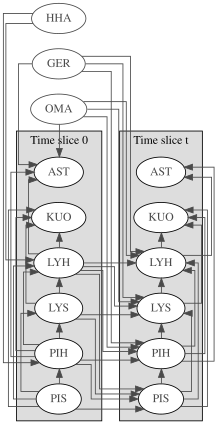

In [6]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

# HUOMIO! Lisää noodi, joka käsittelee kuolleen erikseen! eli siis kaikki tuo on ehdollistettu sillä, että henkilö on elossa.

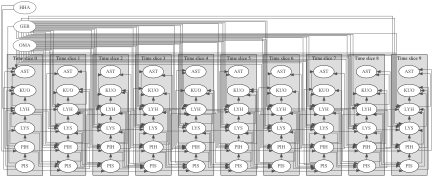

In [9]:
T = 10
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [11]:
ie = gum.LazyPropagation(dbn)
gnb.sideBySide(ie.posterior("PIS3"), ie.posterior("PIS4"), ie.posterior("KUO3"))
for i in range(4):
    ie.setEvidence({"PIS3": i})
    gnb.sideBySide(ie.posterior("PIS3"), ie.posterior("PIS4"), ie.posterior("KUO3"))